# 07 — EDA — merged NetFlow v3 (`UNSW`, `CIC18`, `ToN`, `BoT`)

**Owner:** Ahmed Hamouda · **Phase 4 — Exploratory data analysis** · Cross-Network Intrusion Analysis (CRISP-DM)

Exploratory analysis of the merged NetFlow table (`data/processed/netflow_merged.parquet`, notebook `06_merge_netflow`),
following the course lab (Lab 4). CICIoT2023 has its own EDA in `07_eda_iot23`.

| § | Content | Phase 4 requirement |
|---|---|---|
| 1 | First look: size, quality, rows per family and network | descriptive statistics |
| 2 | Summary statistics of the key variables, overall and per family | descriptive statistics |
| 3 | Histograms and box plots | plots |
| 4 | Correlation: Pearson and Spearman heatmaps | correlation analysis |
| 5 | Relationships: Benign vs attack in each network, port range × family | relationships between variables |
| 6 | Normality check, then two hypothesis tests (Mann–Whitney U, Kolmogorov–Smirnov) | justified hypothesis tests |
| 7 | Conclusion | interpretation |

**Research questions** (phase 1): **SQ1** which traffic characteristics distinguish normal traffic from attacks;
**SQ2** whether the same attack family behaves the same way in different networks.

**One row = one behaviour.** The cleaning merged identical flows into one row with a `count` column
(63,012,224 flows → 17,551,848 rows). The analysis counts behaviours: identical copies of a flow are not independent
observations and would let the floods dominate every result.

## 0 — Setup

In [1]:
import sys; sys.path.append("..")
from src.config import *

import warnings; warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
sns.set_style("whitegrid")

ALPHA = 0.05                                       # significance level of every test
SOURCES = ["UNSW", "CIC18", "ToN", "BoT"]
NAMES = {"UNSW": "UNSW", "CIC18": "CIC-2018", "ToN": "ToN-IoT", "BoT": "BoT-IoT"}

# the 4 key variables: how much is sent, how much comes back, how many packets, how long
KEY = ["IN_BYTES", "OUT_BYTES", "IN_PKTS", "FLOW_DURATION_MILLISECONDS"]
# traffic features shown in the correlation heatmap
CORR = ["IN_BYTES", "OUT_BYTES", "IN_PKTS", "OUT_PKTS", "FLOW_DURATION_MILLISECONDS", "LONGEST_FLOW_PKT",
        "SHORTEST_FLOW_PKT", "SRC_TO_DST_AVG_THROUGHPUT", "SRC_TO_DST_IAT_AVG", "TCP_WIN_MAX_IN",
        "RETRANSMITTED_IN_BYTES", "NUM_PKTS_UP_TO_128_BYTES"]

def save(fig, name):
    fig.savefig(FIG_DIR / f"NetFlow_eda_{name}.png", dpi=120, bbox_inches="tight")

def table(t, name):
    t.to_csv(TABLE_DIR / f"NetFlow_eda_{name}.csv")
    return t

df = pd.read_parquet(PROCESSED_DIR / "netflow_merged.parquet",
                     columns=CORR + ["L4_DST_PORT", "count", "source_dataset", "attack_family", "is_attack"])
df["source_dataset"] = df["source_dataset"].cat.set_categories(SOURCES)
FAMILY_ORDER = [f for f in [BENIGN] + FAMILIES if f in set(df["attack_family"].cat.categories)]
df["attack_family"] = df["attack_family"].cat.set_categories(FAMILY_ORDER)
df["class"] = np.where(df["is_attack"] == 1, "Attack", "Benign")
print(f"{len(df):,} behaviours standing for {int(df['count'].sum()):,} flows")

17,551,848 behaviours standing for 63,012,224 flows


**One sample for plots and tests.** Counts and summary statistics use **all 17.5 million rows**. Box plots,
the correlation heatmap and the tests use **one sample**: up to 10,000 random behaviours from every network × family
group (all rows when a group is smaller). Every family and every network is then represented fairly — without it,
Benign would be 67 % of every plot and Data theft (448 behaviours) would be invisible — and the plots and tests stay
fast. `random_state = 42` makes the sample the same at every run.

In [2]:
# give every row a random number, then keep the 10,000 smallest numbers inside each network x family group
rnd = pd.Series(np.random.default_rng(RANDOM_STATE).random(len(df)), index=df.index)
rank = rnd.groupby([df["source_dataset"], df["attack_family"]], observed=True).rank(method="first")
sample = df[rank.to_numpy() <= 10_000]
print(f"sample: {len(sample):,} behaviours")
pd.crosstab(sample["attack_family"], sample["source_dataset"], margins=True)

sample: 187,418 behaviours


source_dataset,UNSW,CIC18,ToN,BoT,All
attack_family,,,,,
Benign,10000,10000,10000,10000,40000
Denial of service,5360,10000,10000,10000,35360
Reconnaissance,10000,0,10000,10000,30000
Credential attacks,0,10000,10000,0,20000
Web and injection,0,53,10000,0,10053
Malware and botnets,3802,2804,10000,0,16606
Exploitation and intrusion,10000,10000,0,0,20000
Interception and spoofing,0,0,4951,0,4951
Fuzzing and crypto,10000,0,0,0,10000


---
## 1 — First look at the data

In [3]:
print("rows, columns:", df.shape)
print("missing values:", int(df.isna().sum().sum()))
counts = pd.concat({"behaviours": pd.crosstab(df["attack_family"], df["source_dataset"], margins=True, margins_name="All"),
                    "flows": df.pivot_table(index="attack_family", columns="source_dataset", values="count", aggfunc="sum",
                                            observed=False, margins=True, margins_name="All").fillna(0).astype("int64")}, axis=1)
table(counts, "rows_flows_per_family")

rows, columns: (17551848, 18)


missing values: 0


behaviours                                         flows                                        
source_dataset                   UNSW    CIC18      ToN      BoT       All     UNSW     CIC18       ToN       BoT       All
attack_family                                                                                                              
Benign                        1307351  8178232  2282642    21951  11790176  2222930  17392754  15078514     51989  34746187
Denial of service                5360   642600   573277   642187   1863424     5971   1463045   4344712  15185072  20998800
Reconnaissance                  13134        0   225074   898728   1136936    18300         0   1358977   1695132   3072409
Credential attacks                  0    94890   697124        0    792014        0    288515   1594777         0   1883292
Web and injection                   0       53  1831103        0   1831156        0        54   1954859         0   1954913
Malware and botnets              3802     2804    23471        0     30077     4816    111460    105663         0    221939
Exploitation and intrusion      42740    27213        0        0     69953    45125     29209         0         0     74334
Interception and spoofing           0        0     4951        0      4951        0         0      5268         0      5268
Fuzzing and crypto              32713        0        0        0     32713    53467         0         0         0     53467
Data theft                          0        0        0      448       448        0         0         0      1615      1615
All                           1405100  8945792  5637642  1563314  17551848  2350609  19285037  24442770  16933808  63012224

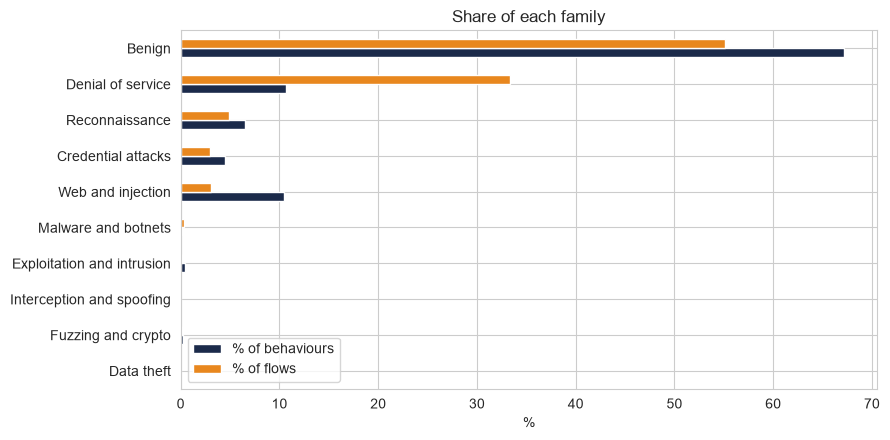

,% of behaviours,% of flows
attack_family,,
Benign,67.17,55.14
Denial of service,10.62,33.32
Reconnaissance,6.48,4.88
Credential attacks,4.51,2.99
Web and injection,10.43,3.10
Malware and botnets,0.17,0.35
Exploitation and intrusion,0.40,0.12
Interception and spoofing,0.03,0.01
Fuzzing and crypto,0.19,0.08


In [4]:
fam = pd.DataFrame({"% of behaviours": df["attack_family"].value_counts(normalize=True) * 100,
                    "% of flows": df.groupby("attack_family", observed=True)["count"].sum().astype("int64") / int(df["count"].sum()) * 100})
fig, ax = plt.subplots(figsize=(9, 4.5))
fam.loc[FAMILY_ORDER[::-1]].plot.barh(ax=ax, color=["#1B2A4A", "#E8871E"])
ax.set_title("Share of each family"); ax.set_xlabel("%"); ax.set_ylabel("")
plt.tight_layout(); save(fig, "families"); plt.show()
fam.round(2)

**Interpretation.** The merged table has **17,551,848 behaviours standing for 63,012,224 flows**, with **no
missing value**.
- **Benign is the majority:** 67 % of the behaviours. Denial of service (11 %) and Web and injection (10 %) are the
  largest attack families; Data theft has only 448 behaviours.
- **Behaviours vs flows:** Denial of service is 11 % of the behaviours but 33 % of the flows — floods repeat the same flow
  many times. Counting behaviours keeps the floods from dominating the analysis.
- **Not every family is in every network:** only Benign and Denial of service exist in all four. Fuzzing comes only from
  UNSW, Interception only from ToN-IoT, Data theft only from BoT-IoT, and Web and injection practically only from ToN-IoT.
  This limits the comparisons across networks (test 2 uses Denial of service for that reason).

---
## 2 — Summary statistics
### 2.1 The key variables (all 17.5 million behaviours)
Centre (mean, median), spread (standard deviation, IQR = Q3 − Q1) and shape (skewness: 0 = symmetric, above 1 =
highly skewed).

In [5]:
def summary(x):
    x = x.astype("float64")
    q1, q2, q3 = x.quantile([0.25, 0.5, 0.75])
    return pd.Series({"mean": x.mean(), "median": q2, "std": x.std(), "Q1": q1, "Q3": q3, "IQR": q3 - q1,
                      "skewness": x.skew(), "min": x.min(), "max": x.max()})

desc = df[KEY].apply(summary).T
table(desc.round(1), "summary")

,mean,median,std,Q1,Q3,IQR,skewness,min,max
IN_BYTES,3725.0,701.0,142790.5,164.0,1623.0,1459.0,357.2,1.0,189027266.0
OUT_BYTES,11337.9,940.0,315029.5,127.0,2239.0,2112.0,194.5,0.0,196978660.0
IN_PKTS,32.9,6.0,1664.4,3.0,10.0,7.0,179.4,1.0,1220131.0
FLOW_DURATION_MILLISECONDS,14549.2,755.0,33204.9,47.0,4057.0,4010.0,2.4,0.0,120999.0


**Interpretation.** All four variables are **strongly right-skewed**:
- the mean is much larger than the median (`IN_BYTES`: 3,725 vs 701 bytes), because a few huge flows pull the mean up
  (the largest carries 189 MB);
- the skewness is far above 1 (357 for `IN_BYTES`); the slides call anything above 1 "highly skewed";
- the standard deviation is larger than the mean.

The **median and the IQR** therefore describe a typical flow better than the mean and the standard deviation, and they
are used in the rest of the notebook. A typical behaviour sends 701 bytes in 6 packets and lasts 0.75 s.
The duration never exceeds 121 s: the NetFlow exporter cuts longer connections into pieces.

### 2.2 Typical value per family (median)

In [6]:
med = df.groupby("attack_family", observed=True)[KEY].median()
table(med, "median_per_family")

,IN_BYTES,OUT_BYTES,IN_PKTS,FLOW_DURATION_MILLISECONDS
attack_family,,,,
Benign,1135.0,1572.0,8.0,1325.0
Denial of service,528.0,1136.0,6.0,10812.0
Reconnaissance,44.0,40.0,1.0,23.0
Credential attacks,481.0,2142.0,6.0,438.0
Web and injection,760.0,1304.0,6.0,304.0
Malware and botnets,288.0,240.0,6.0,1506.0
Exploitation and intrusion,822.0,555.0,10.0,800.0
Interception and spoofing,140.0,258.0,2.0,37.0
Fuzzing and crypto,812.0,336.0,10.0,708.0


**Interpretation.** Each family has its own typical flow:
- **Reconnaissance** is the smallest: 44 bytes, 1 packet, 23 ms — a single probe packet, typical of a scan.
- **Denial of service** lasts the longest (median 10.8 s): connections held open or flooded.
- **Data theft** moves the most data (1,658 bytes sent, 3,380 received, 14 packets).
- **Interception and spoofing** is short and small (140 bytes, 37 ms), like DNS messages.

These differences show that the traffic variables carry information about the type of attack (SQ1).

---
## 3 — Plots of one variable
### 3.1 Histograms (all behaviours, log scale)
The values go from 0 to almost 200 million, so they are plotted as log10(1 + value): each step of 1 on the axis means
×10 (2 = 100, 3 = 1,000, …). The "+1" keeps the zeros on the plot.

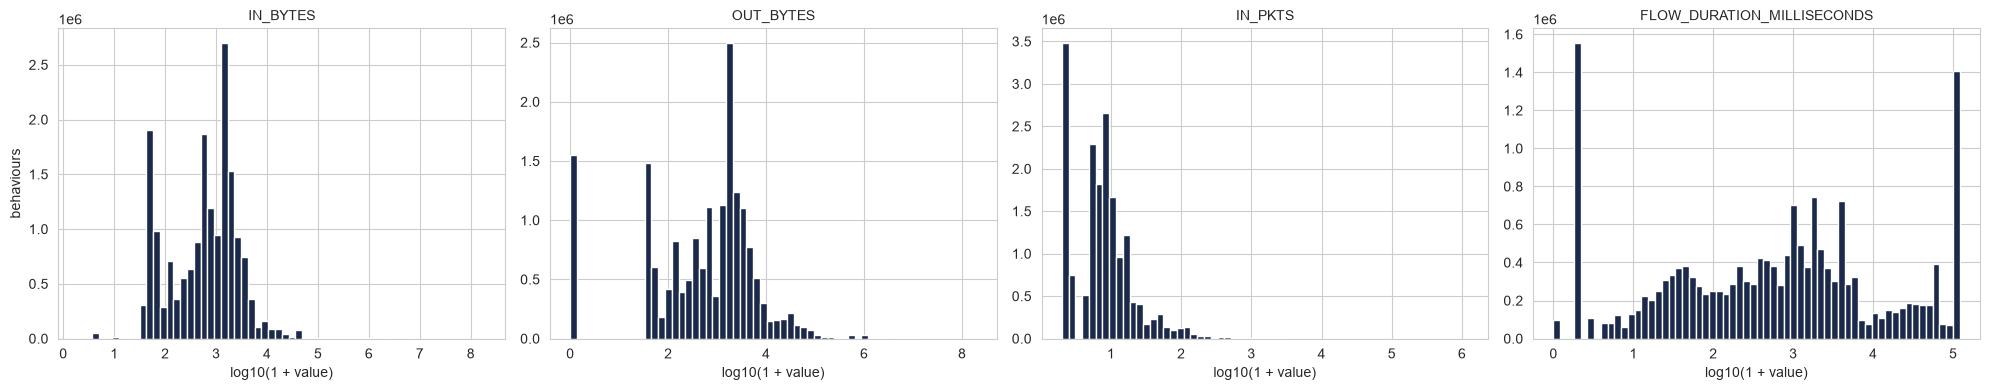

% of behaviours equal to 0: {'IN_BYTES': 0.0, 'OUT_BYTES': 8.8, 'IN_PKTS': 0.0, 'FLOW_DURATION_MILLISECONDS': 0.6}


In [7]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, c in zip(axes, KEY):
    ax.hist(np.log10(1 + df[c].to_numpy()), bins=60, color="#1B2A4A")
    ax.set_title(c, fontsize=10); ax.set_xlabel("log10(1 + value)")
axes[0].set_ylabel("behaviours")
plt.tight_layout(); save(fig, "histograms"); plt.show()
print("% of behaviours equal to 0:", (df[KEY] == 0).mean().mul(100).round(1).to_dict())

**Interpretation.** None of the variables has a bell shape, even on the log scale. The distributions have
several peaks and tall spikes at single values, each with a technical cause:
- `OUT_BYTES` = 0 for 8.8 % of the behaviours: **no answer** (scan of a closed port, flooded victim);
- `IN_PKTS` = 1: one-packet flows (probes, DNS queries);
- `FLOW_DURATION` piles up near 0 ms and at 120 s (the exporter's time limit).

These shapes already suggest that the normality check (§6.1) will fail.

### 3.2 Box plots by family (sample, log scale)

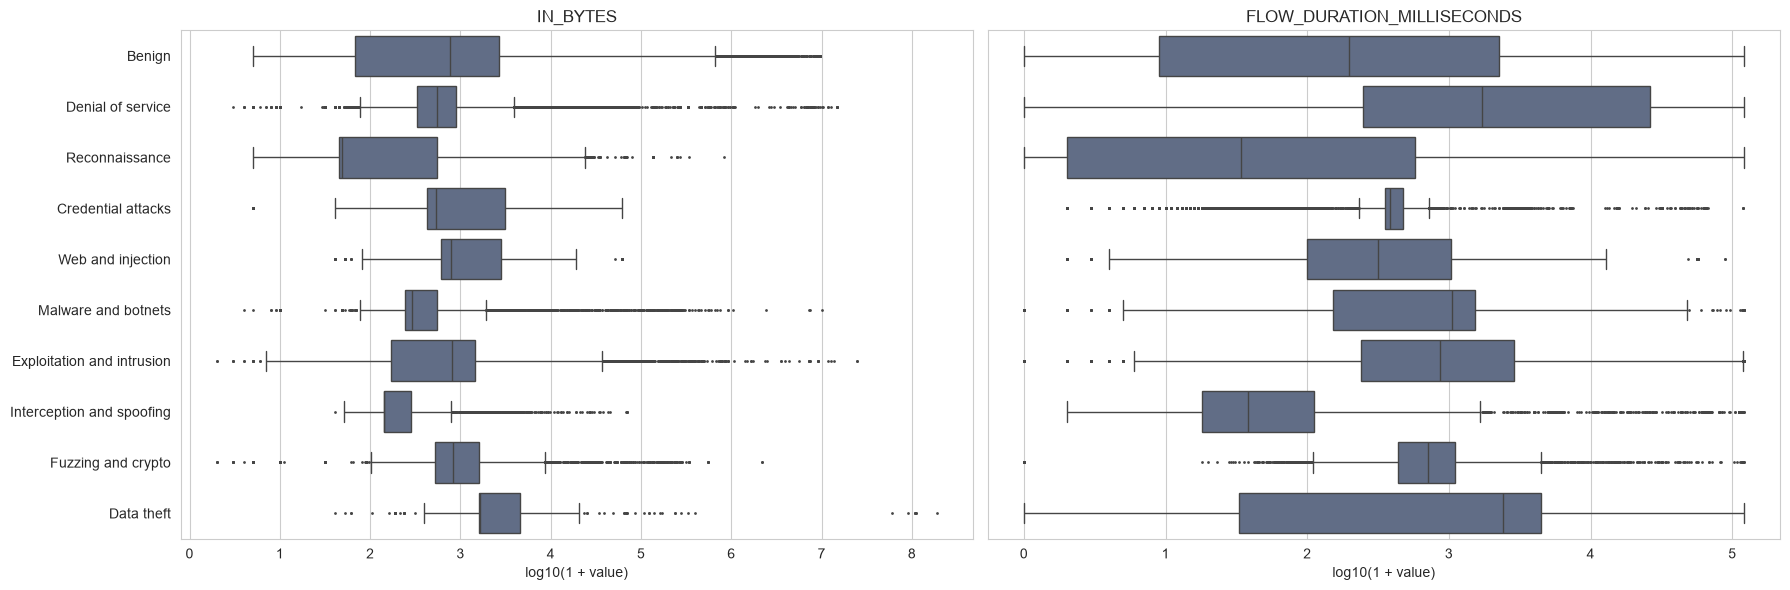

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)
for ax, c in zip(axes, ["IN_BYTES", "FLOW_DURATION_MILLISECONDS"]):
    sns.boxplot(x=np.log10(1 + sample[c]), y=sample["attack_family"].astype(str), order=FAMILY_ORDER, ax=ax,
                color="#5B6B8C", fliersize=1)
    ax.set_title(c); ax.set_xlabel("log10(1 + value)"); ax.set_ylabel("")
plt.tight_layout(); save(fig, "boxplots_by_family"); plt.show()

**Interpretation.** The families are clearly shifted from each other: Reconnaissance has the smallest byte
counts and the shortest flows, Denial of service the longest flows, Data theft the most bytes. But **the Benign box
covers almost the whole range of the attack families**: no single variable separates normal traffic from all attacks,
so a model will need several variables together. The points beyond the whiskers are mostly real attacks (big floods,
long connections) and are kept.

---
## 4 — Correlation
**Pearson** measures a straight-line relationship and is pulled by extreme values. **Spearman** works on ranks and
measures any relationship that goes in one direction (monotonic); it is not affected by extreme values. Both are
computed on the sample, for 12 traffic features.

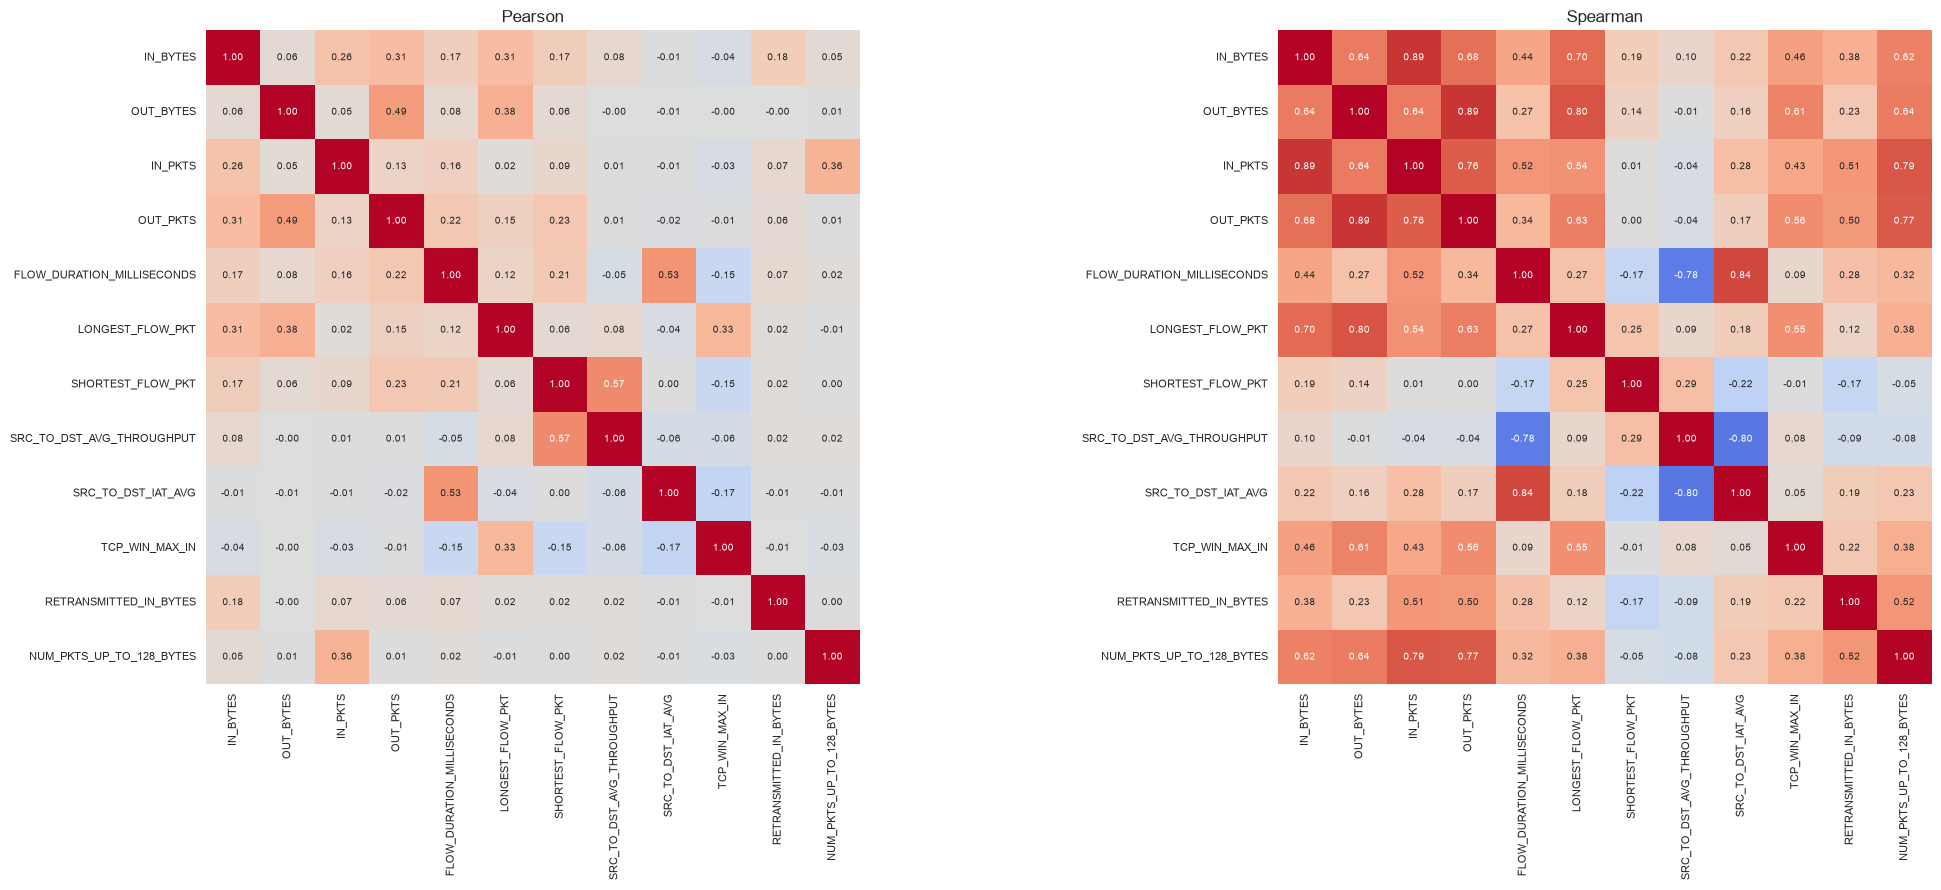

strongest Spearman pairs:


IN_BYTES                    IN_PKTS                     0.89
OUT_BYTES                   OUT_PKTS                    0.89
FLOW_DURATION_MILLISECONDS  SRC_TO_DST_IAT_AVG          0.84
SRC_TO_DST_AVG_THROUGHPUT   SRC_TO_DST_IAT_AVG         -0.80
OUT_BYTES                   LONGEST_FLOW_PKT            0.80
IN_PKTS                     NUM_PKTS_UP_TO_128_BYTES    0.79
dtype: float64

largest differences Pearson vs Spearman:


,,Pearson,Spearman
OUT_PKTS,NUM_PKTS_UP_TO_128_BYTES,0.01,0.77
SRC_TO_DST_AVG_THROUGHPUT,SRC_TO_DST_IAT_AVG,-0.06,-0.80
FLOW_DURATION_MILLISECONDS,SRC_TO_DST_AVG_THROUGHPUT,-0.05,-0.78
IN_BYTES,IN_PKTS,0.26,0.89


In [9]:
pear = sample[CORR].corr("pearson")
spear = sample[CORR].corr("spearman")
fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, (m, title) in zip(axes, [(pear, "Pearson"), (spear, "Spearman")]):
    sns.heatmap(m, cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7},
                square=True, cbar=False, ax=ax)
    ax.set_title(title); ax.tick_params(labelsize=8)
plt.tight_layout(); save(fig, "correlation"); plt.show()
table(spear.round(2), "spearman")
up = spear.where(np.triu(np.ones(spear.shape, bool), 1)).stack()
print("strongest Spearman pairs:"); display(up.reindex(up.abs().sort_values(ascending=False).index).head(6).round(2))
print("largest differences Pearson vs Spearman:")
gap = (spear - pear).where(np.triu(np.ones(spear.shape, bool), 1)).stack().abs().sort_values(ascending=False).head(4)
pd.DataFrame({"Pearson": [pear.loc[a, b] for a, b in gap.index], "Spearman": [spear.loc[a, b] for a, b in gap.index]},
             index=gap.index).round(2)

**Interpretation.** The two heatmaps look very different. Pearson finds almost no relationship (most values
near 0), while Spearman finds strong ones — for example `IN_BYTES`–`IN_PKTS`: r = 0.26 but ρ = 0.89. The data are very
skewed, and a few gigantic flows dominate Pearson, which hides the real relationships. **Spearman is the right
coefficient for this data.**

Main Spearman relationships:
- **volume:** bytes and packets rise together (`IN_BYTES`–`IN_PKTS` 0.89, `OUT_BYTES`–`OUT_PKTS` 0.89), and the more
  data a flow carries, the bigger its largest packet (`OUT_BYTES`–`LONGEST_FLOW_PKT` 0.80);
- **time:** longer flows have longer gaps between packets (0.84) and a lower throughput (−0.78).

Strongly correlated columns carry similar information; feature selection in phase 5 will keep one of each group.

---
## 5 — Relationships between variables
### 5.1 Benign vs attack in each network (number × category)
Box plots from the sample; the medians in the table are computed on all behaviours.

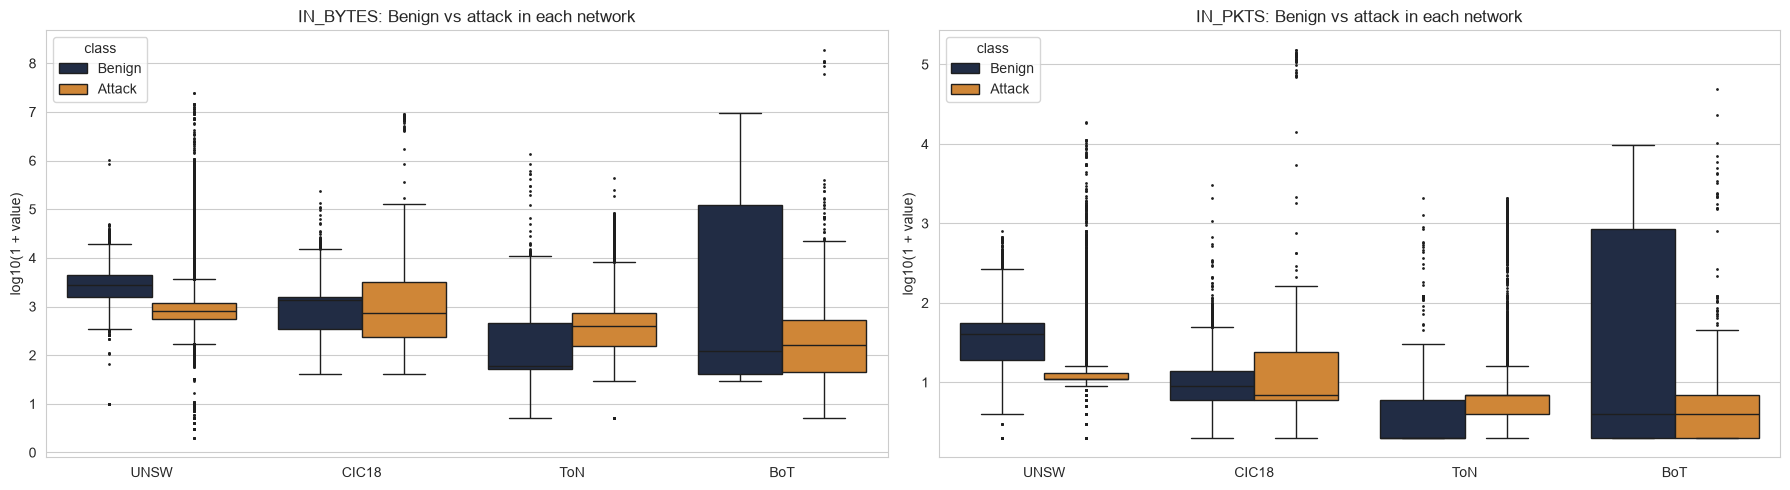

class            Benign                                                Attack                                             
               IN_BYTES OUT_BYTES IN_PKTS FLOW_DURATION_MILLISECONDS IN_BYTES OUT_BYTES IN_PKTS FLOW_DURATION_MILLISECONDS
source_dataset                                                                                                            
UNSW             2750.0    8824.0    40.0                       95.0    814.0     336.0    10.0                      716.0
CIC18            1369.0    1873.0     8.0                     2845.0    510.0    1147.0     5.0                     3334.0
ToN                65.0      52.0     1.0                       22.0    637.0    1155.0     6.0                      377.0
BoT               120.0      40.0     3.0                       31.0     44.0      40.0     1.0                       51.0

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for ax, c in zip(axes, ["IN_BYTES", "IN_PKTS"]):
    sns.boxplot(x=sample["source_dataset"].astype(str), y=np.log10(1 + sample[c]), hue=sample["class"], order=SOURCES,
                hue_order=["Benign", "Attack"], palette={"Benign": "#1B2A4A", "Attack": "#E8871E"}, ax=ax, fliersize=1)
    ax.set_title(f"{c}: Benign vs attack in each network"); ax.set_xlabel(""); ax.set_ylabel("log10(1 + value)")
plt.tight_layout(); save(fig, "benign_vs_attack"); plt.show()
med_net = df.groupby(["source_dataset", "class"], observed=True)[KEY].median().unstack("class")
table(med_net.swaplevel(axis=1)[["Benign", "Attack"]], "median_benign_attack")

**Interpretation.** This is the most important relationship of the analysis: **the difference between
Benign and attack traffic is not the same in every network — it even points in opposite directions.**
- **UNSW:** attacks are *smaller* than normal traffic (814 vs 2,750 bytes, 10 vs 40 packets).
- **ToN-IoT:** attacks are *larger* (637 vs 65 bytes, 6 vs 1 packet), because ToN-IoT's normal traffic is mostly
  tiny one-packet flows.
- **CIC-2018 and BoT-IoT:** the two classes are close.

Normal traffic itself is very different from one network to another (40 packets in UNSW, 1 in ToN-IoT). A rule such as
"attacks send more bytes" is true in one network and false in another. Test 1 (§6.2) checks this formally.

### 5.2 Destination port range × family (category × category)
Ports are grouped into the official ranges: well-known 0–1023 (standard services such as 80 HTTP, 22 SSH, 53 DNS),
registered 1024–49151, dynamic 49152–65535. Row percentages, all behaviours.

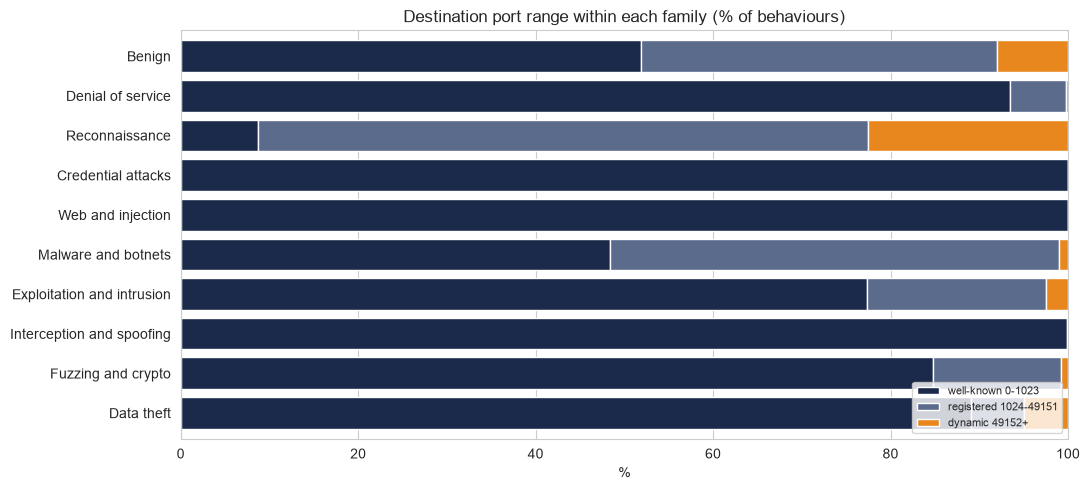

port_range,well-known 0-1023,registered 1024-49151,dynamic 49152+
attack_family,,,
Benign,51.9,40.1,8.0
Denial of service,93.5,6.3,0.2
Reconnaissance,8.7,68.8,22.5
Credential attacks,99.9,0.1,0.0
Web and injection,100.0,0.0,0.0
Malware and botnets,48.4,50.6,1.0
Exploitation and intrusion,77.4,20.2,2.4
Interception and spoofing,99.9,0.1,0.0
Fuzzing and crypto,84.8,14.5,0.7


In [11]:
df["port_range"] = pd.cut(df["L4_DST_PORT"], [-1, 1023, 49151, 65535],
                          labels=["well-known 0-1023", "registered 1024-49151", "dynamic 49152+"])
ct = pd.crosstab(df["attack_family"], df["port_range"], normalize="index") * 100
fig, ax = plt.subplots(figsize=(11, 5))
ct.loc[FAMILY_ORDER[::-1]].plot.barh(stacked=True, ax=ax, width=0.8, color=["#1B2A4A", "#5B6B8C", "#E8871E"])
ax.set_title("Destination port range within each family (% of behaviours)"); ax.set_xlabel("%"); ax.set_ylabel("")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); save(fig, "port_range_by_family"); plt.show()
table(ct.round(1), "port_range_by_family")

**Interpretation.** The port range is strongly linked to the family:
- **Web, Credential, Interception and Denial-of-service** traffic goes almost only to **well-known ports** (93–100 %):
  these attacks target standard services (80 HTTP, 22 SSH, 53 DNS).
- **Reconnaissance** goes 91 % to registered and dynamic ports: a scan tries many ports, while a real service uses a
  few known ones.
- **Benign** traffic is mixed (52 % well-known, 40 % registered).

The destination port is therefore a useful variable for recognising the type of attack (SQ1). It is encoded as a
category in phase 5.

---
## 6 — Hypothesis tests
### 6.1 Normality check: which kind of test can we use?
The t-test and ANOVA of the lab assume roughly normal data. Shapiro–Wilk and D'Agostino–Pearson test
**H₀: the data come from a normal distribution**, on 5,000 random behaviours (Shapiro–Wilk's limit), raw and after
log(1 + x); the Q-Q plots show the same visually (points on the line = normal).

skewness     Shapiro p   D'Agostino p normal?
variable                   scale                                                  
IN_BYTES                   raw          18.95  2.192574e-94   0.000000e+00      no
                           log(1+x)      1.10  3.376621e-44  2.661366e-238      no
OUT_BYTES                  raw          25.16  1.149687e-94   0.000000e+00      no
                           log(1+x)     -0.36  4.058659e-43   9.428190e-37      no
IN_PKTS                    raw          48.85  1.650261e-95   0.000000e+00      no
                           log(1+x)      1.89  3.707323e-57   0.000000e+00      no
FLOW_DURATION_MILLISECONDS raw           3.85  1.064220e-84   0.000000e+00      no
                           log(1+x)     -0.14  2.109593e-32   2.458629e-22      no

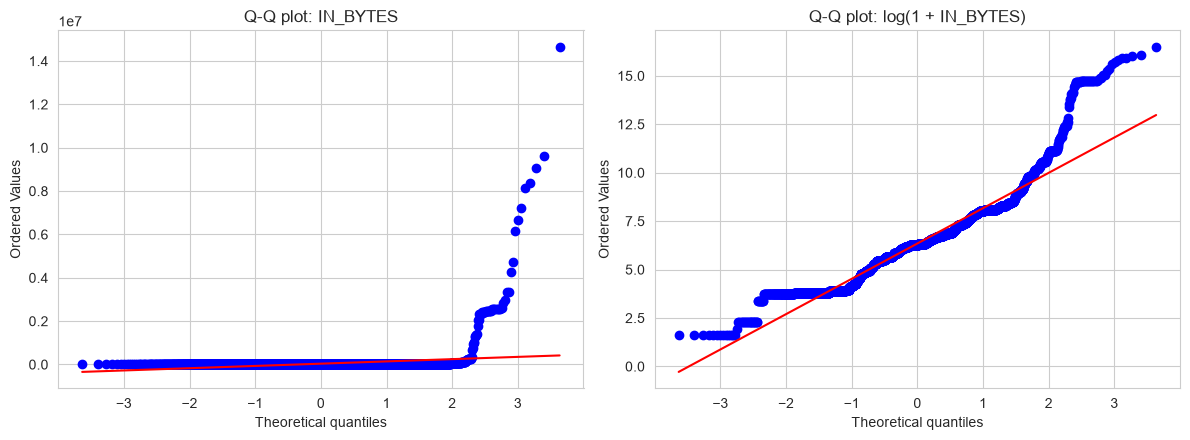

In [ ]:
n5 = sample.sample(5_000, random_state=RANDOM_STATE)
rows_ = []
for c in KEY:
    for scale, x in [("raw", n5[c].astype(float)), ("log(1+x)", np.log1p(n5[c].astype(float)))]:
        rows_.append({"variable": c, "scale": scale, "skewness": round(x.skew(), 2),
                      "Shapiro p": stats.shapiro(x).pvalue, "D'Agostino p": stats.normaltest(x).pvalue})
norm = pd.DataFrame(rows_).set_index(["variable", "scale"])
norm["normal?"] = np.where((norm["Shapiro p"] >= ALPHA) & (norm["D'Agostino p"] >= ALPHA), "yes", "no")
display(table(norm, "normality"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
stats.probplot(n5["IN_BYTES"].astype(float), dist="norm", plot=axes[0]); axes[0].set_title("Q-Q plot: IN_BYTES")
stats.probplot(np.log1p(n5["IN_BYTES"].astype(float)), dist="norm", plot=axes[1]); axes[1].set_title("Q-Q plot: log(1 + IN_BYTES)")
plt.tight_layout(); save(fig, "normality_qq"); plt.show()

**Interpretation.** Visually, no variable follows the normal curve. On the raw scale the Q-Q points lie flat
along the bottom and then shoot up (a few huge values). After log(1 + x) they come closer to the line but form a
**staircase**, because many flows share exactly the same value. Both formal tests reject normality for every variable
on both scales (all p-values below 10⁻²⁰). With 5,000 values the tests would also catch small, harmless departures,
but here the departures are large: the raw skewness is between 4 and 49, and the plots show it clearly. The log
transform helps the shape (`IN_BYTES` skewness 19 → 1.1) but does not make the data normal.

**Practical conclusion:** the t-test and ANOVA, which compare means and assume normal groups, are not suitable. The
tests below use the **non-parametric** alternatives from the Chapter 4 slides, which work on ranks and need no
normality. The CICIoT2023 analysis reached the same conclusion (`07_eda_iot23`).

### How the tests are read
- **Non-parametric tests** (no normality needed), from the Chapter 4 slides: Mann–Whitney U instead of the two-sample
  t-test; Kolmogorov–Smirnov to compare two whole distributions.
- With hundreds of thousands of rows, even a tiny difference gives p ≈ 0. The p-value says *whether* there is a
  difference; the **effect size** says *how big* it is, and the conclusion rests on it.
- Several tests answer the same question, so the p-values are multiplied by the number of tests (**Bonferroni
  correction**) before comparing them with α = 0.05.

### 6.2 Test 1 (SQ1) — Mann–Whitney U: is attack traffic different from Benign traffic?
1. **H₀:** in a given network, attack and Benign behaviours have the same distribution of the variable.
   **H₁:** the distributions differ (two-sided).
2. **Test and assumptions:** Mann–Whitney U — two independent groups (different behaviours), numeric variable, no
   normality needed (§6.1). Run inside each network, on **all** its behaviours.
3. **Effect size:** rank-biserial **r** = 2U / (n₁·n₂) − 1, between −1 and +1. It is the probability that a random attack
   is larger than a random Benign behaviour, minus the opposite. **r > 0: attacks larger; r < 0: attacks smaller.**
   |r| < 0.1 negligible, < 0.3 small, < 0.5 medium, ≥ 0.5 large.
   In plain words, **P(attack > Benign) = (1 + r) / 2** is the chance that a random attack behaviour is larger than a
   random Benign behaviour (ties counted half): 50 % means no difference.
4. **95 % confidence interval of the difference in medians** (attack − Benign), from the distribution-free confidence
   interval of each median (ranks n/2 ± 1.96·√n/2 of the sorted values — no normality needed).

In [ ]:
def size(r):
    r = abs(r)
    return "negligible" if r < 0.1 else "small" if r < 0.3 else "medium" if r < 0.5 else "large"

def median_ci(x):
    """Distribution-free 95% confidence interval of the median: the values at ranks n/2 +- 1.96*sqrt(n)/2."""
    x = np.sort(x); n = len(x); k = 1.96 * np.sqrt(n) / 2
    return x[max(int(np.floor(n / 2 - k)), 0)], x[min(int(np.ceil(n / 2 + k)), n - 1)]

rows_ = []
for s in SOURCES:
    d = df[df["source_dataset"] == s]
    for c in KEY:
        a = d.loc[d["is_attack"] == 1, c].to_numpy(); b = d.loc[d["is_attack"] == 0, c].to_numpy()
        res = stats.mannwhitneyu(a, b, method="asymptotic")
        (a_lo, a_hi), (b_lo, b_hi) = median_ci(a), median_ci(b)
        r = 2 * res.statistic / (len(a) * len(b)) - 1
        rows_.append({"network": NAMES[s], "variable": c, "n attack": len(a), "n Benign": len(b),
                      "median attack": np.median(a), "median Benign": np.median(b),
                      "CI low": a_lo - b_hi, "CI high": a_hi - b_lo,
                      "U": res.statistic, "p": res.pvalue, "r": r, "P(attack > Benign) %": 100 * (1 + r) / 2})
mw = pd.DataFrame(rows_)
mw["p Bonferroni"] = (mw["p"] * len(mw)).clip(upper=1)
mw["decision"] = np.where(mw["p Bonferroni"] < ALPHA, "reject H0", "keep H0")
mw["effect"] = mw["r"].map(size)
table(mw.set_index(["network", "variable"]), "mann_whitney")
display(mw.pivot(index="variable", columns="network", values="r").loc[KEY, [NAMES[s] for s in SOURCES]].round(2)
        .style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1).format("{:.2f}"))
mw.set_index(["network", "variable"])[["median attack", "median Benign", "CI low", "CI high", "U", "p Bonferroni",
                                       "r", "P(attack > Benign) %", "effect", "decision"]].round(3)

network,UNSW,CIC-2018,ToN-IoT,BoT-IoT
variable,,,,
IN_BYTES,-0.50,-0.11,0.51,-0.10
OUT_BYTES,-0.73,0.04,0.69,-0.13
IN_PKTS,-0.62,-0.11,0.59,-0.22
FLOW_DURATION_MILLISECONDS,0.46,-0.05,0.36,0.12


median attack  median Benign  CI low  CI high             U  p Bonferroni      r  P(attack > Benign) %      effect   decision
network  variable                                                                                                                                                 
UNSW     IN_BYTES                            814.0         2750.0   -1938    -1934  3.185068e+10           0.0 -0.502                24.924       large  reject H0
         OUT_BYTES                           336.0         8824.0   -8488    -8488  1.748732e+10           0.0 -0.726                13.684       large  reject H0
         IN_PKTS                              10.0           40.0     -30      -30  2.456599e+10           0.0 -0.616                19.223       large  reject H0
         FLOW_DURATION_MILLISECONDS          716.0           95.0     616      625  9.349674e+10           0.0  0.463                73.163      medium  reject H0
CIC-2018 IN_BYTES                            510.0         1369.0    -861     -858  2.801848e+12           0.0 -0.107                44.635       small  reject H0
         OUT_BYTES                          1147.0         1873.0    -726     -726  3.257096e+12           0.0  0.038                51.887  negligible  reject H0
         IN_PKTS                               5.0            8.0      -3       -3  2.800254e+12           0.0 -0.108                44.609       small  reject H0
         FLOW_DURATION_MILLISECONDS         3334.0         2845.0     411      582  2.986962e+12           0.0 -0.048                47.584  negligible  reject H0
ToN-IoT  IN_BYTES                            637.0           65.0     572      575  5.786491e+12           0.0  0.511                75.559       large  reject H0
         OUT_BYTES                          1155.0           52.0    1098     1106  6.466715e+12           0.0  0.689                84.441       large  reject H0
         IN_PKTS                               6.0            1.0       5        5  6.069265e+12           0.0  0.585                79.251       large  reject H0
         FLOW_DURATION_MILLISECONDS          377.0           22.0     354      356  5.208277e+12           0.0  0.360                68.009      medium  reject H0
BoT-IoT  IN_BYTES                             44.0          120.0    -104      -76  1.514868e+10           0.0 -0.105                44.773       small  reject H0
         OUT_BYTES                            40.0           40.0       0        0  1.470447e+10           0.0 -0.131                43.460       small  reject H0
         IN_PKTS                               1.0            3.0      -2       -2  1.317824e+10           0.0 -0.221                38.949       small  reject H0
         FLOW_DURATION_MILLISECONDS           51.0           31.0     -88       32  1.898825e+10           0.0  0.122                56.121       small  reject H0

**Interpretation.**
- **H₀:** in each network, attack and Benign behaviours have the same distribution of the variable.
  **H₁:** the distributions differ.
- **Assumptions checked and test chosen (why):** the two groups are different behaviours, so they are independent.
  Normality is rejected (§6.1), so the two-sample t-test is not suitable and its rank-based alternative, the
  Mann–Whitney U test, is used. It runs on all behaviours of each network (from 21,951 to 8,178,232 per group).
- **Test and p-value:** 16 tests (4 networks × 4 variables). For example, UNSW `OUT_BYTES`: U = 1.75 × 10¹⁰,
  p < 10⁻³⁰⁰. All 16 Bonferroni-corrected p-values are below 10⁻¹⁸⁰.
- **Decision (α = 0.05):** reject H₀ in all 16 tests.
- **Conclusion in plain language:** the size and the direction of the difference depend on the network.

| Network | Example | Median attack vs Benign (95 % CI of the difference) | r | P(attack > Benign) | Effect |
|---|---|---|---|---|---|
| UNSW | `OUT_BYTES` | 336 vs 8,824 bytes (−8,488 to −8,488) | −0.73 | 14 % | large, attacks **smaller** |
| ToN-IoT | `OUT_BYTES` | 1,155 vs 52 bytes (+1,098 to +1,106) | +0.69 | 84 % | large, attacks **larger** |
| CIC-2018 | `IN_BYTES` | 510 vs 1,369 bytes (−861 to −858) | −0.11 | 45 % | small |
| BoT-IoT | `IN_PKTS` | 1 vs 3 packets (−2 to −2) | −0.22 | 39 % | small |

In UNSW, a random attack flow receives more data than a random Benign flow only 14 % of the time; in ToN-IoT, 84 % of
the time. The confidence intervals are very narrow because they use millions of behaviours: the medians are known
almost exactly. Two cases show why the whole distribution matters, not only the median:
- in CIC-2018, `OUT_BYTES` has a lower median for attacks but r is slightly positive (+0.04), because the two
  distributions cross; the effect is negligible either way;
- in BoT-IoT, the confidence interval of the duration difference includes 0 (−88 to +32 ms): the medians may be equal,
  yet the test still finds a small difference in the distributions (r = +0.12).

**Answer to SQ1:** attack traffic does differ from normal traffic, often strongly, but which variable shows it and in
which direction depends on the network. A rule learned in one network ("attacks are small") can be wrong in another.

### 6.3 Test 2 (SQ2) — Kolmogorov–Smirnov: does the same attack family behave the same way in every network?
**Denial of service** is the only attack family present in all four networks.
1. **H₀:** Denial-of-service flows have the same distribution in the two networks. **H₁:** the distributions differ.
2. **Test and assumptions:** two-sample Kolmogorov–Smirnov — two independent samples, numeric variable, no normality
   needed. It compares the **whole** distributions (not only the medians), which is what "behaves the same way" means.
   Run for every pair of networks (6 pairs) on two variables, using the sample (up to 10,000 behaviours per network).
3. **Effect size:** the KS statistic **D** = the largest vertical gap between the two cumulative curves, from 0 (identical)
   to 1 (no overlap at all). D < 0.1 practically the same, 0.1–0.3 moderately different, > 0.3 clearly different.

n1     n2  median 1  median 2      D    p  p Bonferroni   decision               reading
pair                variable                                                                                                               
UNSW vs CIC-2018    IN_BYTES                     5360  10000     814.0     485.0  0.493  0.0           0.0  reject H0     clearly different
                    FLOW_DURATION_MILLISECONDS   5360  10000     650.5    8889.0  0.510  0.0           0.0  reject H0     clearly different
UNSW vs ToN-IoT     IN_BYTES                     5360  10000     814.0     874.0  0.151  0.0           0.0  reject H0  moderately different
                    FLOW_DURATION_MILLISECONDS   5360  10000     650.5     442.5  0.263  0.0           0.0  reject H0  moderately different
UNSW vs BoT-IoT     IN_BYTES                     5360  10000     814.0     420.0  0.483  0.0           0.0  reject H0     clearly different
                    FLOW_DURATION_MILLISECONDS   5360  10000     650.5   28749.0  0.953  0.0           0.0  reject H0     clearly different
CIC-2018 vs ToN-IoT IN_BYTES                    10000  10000     485.0     874.0  0.484  0.0           0.0  reject H0     clearly different
                    FLOW_DURATION_MILLISECONDS  10000  10000    8889.0     442.5  0.594  0.0           0.0  reject H0     clearly different
CIC-2018 vs BoT-IoT IN_BYTES                    10000  10000     485.0     420.0  0.212  0.0           0.0  reject H0  moderately different
                    FLOW_DURATION_MILLISECONDS  10000  10000    8889.0   28749.0  0.506  0.0           0.0  reject H0     clearly different
ToN-IoT vs BoT-IoT  IN_BYTES                    10000  10000     874.0     420.0  0.536  0.0           0.0  reject H0     clearly different
                    FLOW_DURATION_MILLISECONDS  10000  10000     442.5   28749.0  0.995  0.0           0.0  reject H0     clearly different

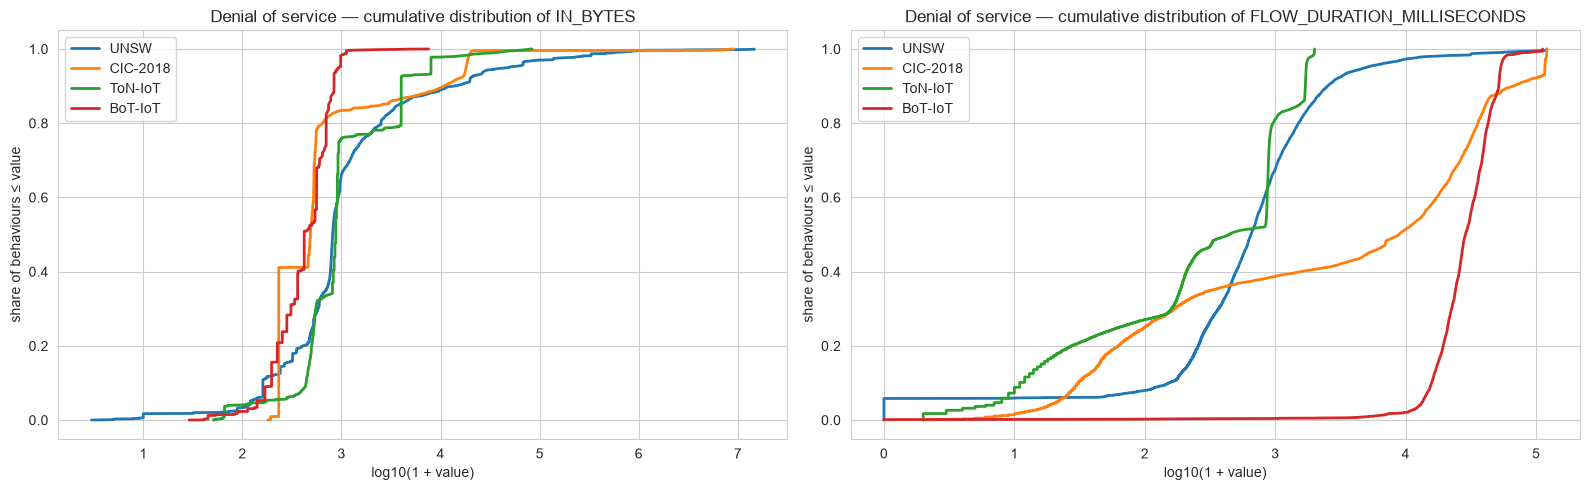

In [ ]:
dos = sample[sample["attack_family"] == "Denial of service"]
rows_ = []
for i, s1 in enumerate(SOURCES):
    for s2 in SOURCES[i + 1:]:
        for c in ["IN_BYTES", "FLOW_DURATION_MILLISECONDS"]:
            x1, x2 = dos.loc[dos["source_dataset"] == s1, c], dos.loc[dos["source_dataset"] == s2, c]
            k = stats.ks_2samp(x1, x2)
            rows_.append({"pair": f"{NAMES[s1]} vs {NAMES[s2]}", "variable": c, "n1": len(x1), "n2": len(x2),
                          "median 1": x1.median(), "median 2": x2.median(), "D": k.statistic, "p": k.pvalue})
ks = pd.DataFrame(rows_)
ks["p Bonferroni"] = (ks["p"] * len(ks)).clip(upper=1)
ks["decision"] = np.where(ks["p Bonferroni"] < ALPHA, "reject H0", "keep H0")
ks["reading"] = pd.cut(ks["D"], [-0.01, 0.1, 0.3, 1.01], labels=["same", "moderately different", "clearly different"])
display(table(ks.set_index(["pair", "variable"]), "ks_dos").round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, c in zip(axes, ["IN_BYTES", "FLOW_DURATION_MILLISECONDS"]):
    for s in SOURCES:
        x = np.sort(np.log10(1 + dos.loc[dos["source_dataset"] == s, c].to_numpy()))
        ax.plot(x, np.arange(1, len(x) + 1) / len(x), lw=2, label=NAMES[s])
    ax.set_title(f"Denial of service — cumulative distribution of {c}")
    ax.set_xlabel("log10(1 + value)"); ax.set_ylabel("share of behaviours ≤ value"); ax.legend()
plt.tight_layout(); save(fig, "ks_dos"); plt.show()

**Interpretation.**
- **H₀:** Denial-of-service flows have the same distribution in the two networks. **H₁:** the distributions differ.
- **Assumptions checked and test chosen (why):** the two samples come from different networks, so they are independent.
  Normality is rejected (§6.1). The question is whether the whole behaviour is the same, not only the centre, so the
  two-sample Kolmogorov–Smirnov test is used: it compares the complete cumulative distributions. 6 pairs of networks ×
  2 variables = 12 tests, with up to 10,000 behaviours per network.
- **Test and p-value:** the largest effect is ToN-IoT vs BoT-IoT on the duration: D = 0.99, p < 10⁻³⁰⁰. The smallest
  effect is UNSW vs ToN-IoT on the bytes: D = 0.15, p = 3 × 10⁻⁶⁹. All 12 Bonferroni-corrected p-values are below 10⁻⁶⁸.
- **Decision (α = 0.05):** reject H₀ in all 12 tests.
- **Conclusion in plain language:** a denial-of-service flow lasts a median of **0.4 s in ToN-IoT** but **29 s in
  BoT-IoT**, and with D = 0.99 the two distributions barely overlap at all. Over the 12 comparisons:
  - 9 are clearly different (D > 0.3);
  - 3 are moderately different (D between 0.1 and 0.3);
  - none is the same.

  The cumulative curves show it: the four networks' curves are far apart instead of lying on top of each other.

**Answer to SQ2:** the same attack family does **not** produce the same traffic in different networks. The testbeds
used different tools, victims and settings, and these change the flows more than the attack type keeps them alike.

---
## 7 — Conclusion

### Wrap-up — what did the exploration tell us?

**Three most important findings.**
1. **SQ1:** attack traffic differs from normal traffic, but the direction depends on the network. In UNSW, attacks
   are smaller than Benign traffic (r down to −0.73); in ToN-IoT they are larger (r up to +0.69). No single variable
   separates attacks from normal traffic everywhere.
2. **SQ2:** the same attack family does not behave the same way in different networks. Denial of service lasts a
   median of 0.4 s in ToN-IoT and 29 s in BoT-IoT (KS D = 0.99), and none of the 12 comparisons finds the same
   distribution.
3. **The families have different profiles:** one-packet scans, long denial-of-service connections, large data-theft
   transfers. The destination port range is strongly linked to the family (scans use high ports, web and credential
   attacks use well-known ports). The variables do carry information about the type of attack.

**Data-quality caveat.** The traffic is far from normal (strong skewness, many repeated technical values such as the
exporter's 120 s time limit). Some differences between networks therefore come from how each testbed was built and
recorded, not only from the attacks. Because the data are so large, every p-value is close to 0, so the conclusions
rest on the effect sizes (r, D).

**Follow-up question.** No single variable separates attacks from normal traffic in all four networks. Can a
**combination** of variables do it, and how much accuracy is lost on a network the model has never seen (SQ3)?

**Next steps (phase 5):**
- log-transform the volume and time variables;
- encode the destination port as a category;
- keep one variable from each strongly correlated group.